In [1]:
import pandas as pd
import os, json, time, math
import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer
import optuna
import matplotlib.pyplot as plt
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.dimensionality import BaseDimensionalityReduction
from sklearn.feature_extraction.text import CountVectorizer
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel



c:\Users\Rafael\Documents\GitHub\Dissertacao_UE\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
df = pd.read_csv('speeches_processed.csv')

In [6]:
n_words = df["speech_en"].astype(str).str.split().str.len()
print(n_words.describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(0))
for limite in [200, 280, 500, 1500]:
    print(f"Acima de {limite} palavras: {(n_words > limite).mean():.1%}")

count    563696.0
mean        192.0
std         192.0
min           1.0
50%         160.0
75%         216.0
90%         344.0
99%         928.0
max        8541.0
Name: speech_en, dtype: float64
Acima de 200 palavras: 30.2%
Acima de 280 palavras: 15.3%
Acima de 500 palavras: 4.6%
Acima de 1500 palavras: 0.3%


In [7]:
DATE_COL = "date"

df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df["year"] = df[DATE_COL].dt.year

BENCH_YEARS = [2015, 2021]
df_bench = df[df["year"].isin(BENCH_YEARS)].copy().reset_index(drop=True)

In [8]:
import os, json
import numpy as np
import pandas as pd

SEED = 42
MIN_TOKENS = 20   # o mesmo do LDA (só serve para verificação)

VARIANTS = {
    "base":    "speech_no_custom_stopwords",
    "lemma":   "speech_lemmatized",
    "stemmed": "speech_stemmed",
}

# ajusta o caminho se este notebook estiver noutra pasta
SPLITS_PATH = "lda_bayes/splits.json"


def to_text(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        return " ".join(map(str, x))
    return "" if pd.isna(x) else str(x)


# df_bench = ...   <- carregar exatamente como no notebook do LDA

# ---------------- Carregar o split do LDA ----------------
splits = json.load(open(SPLITS_PATH))
train_idx = pd.Index(splits["train"])
val_idx   = pd.Index(splits["val"])
test_idx  = pd.Index(splits["test"])
all_idx = train_idx.append(val_idx).append(test_idx)

# verificação 1: todos os ids existem no df_bench
missing = all_idx.difference(df_bench.index)
assert len(missing) == 0, (f"{len(missing)} ids do split não existem no df_bench: "
                           "o índice não é o mesmo do notebook do LDA")

# ---------------- Reconstruir os textos ----------------
texts = {v: df_bench.loc[all_idx, c].apply(to_text) for v, c in VARIANTS.items()}

# verificação 2: no LDA só ficaram discursos com >= MIN_TOKENS em todas as variantes
for v, t in texts.items():
    n_short = (t.str.split().str.len() < MIN_TOKENS).sum()
    if n_short:
        print(f"ATENÇÃO {v}: {n_short} discursos curtos. O índice pode estar desalinhado.")

print(f"treino={len(train_idx)}  validação={len(val_idx)}  teste={len(test_idx)}")

treino=52990  validação=13248  teste=16560


In [12]:


# ---------------- Configuração ----------------
EMB_DIR = "bertopic_embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

EMB_MODELS = {
    "minilm": "sentence-transformers/all-MiniLM-L6-v2",
    "mpnet":  "sentence-transformers/all-mpnet-base-v2",
}
CHUNK_WORDS = 150   # igual nos dois modelos (cabe no limite de 256 do MiniLM)
BATCH_SIZE = 64     # baixa para 32 se faltar memória
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

# split de cada documento (o mesmo do LDA)
split_of = pd.concat([
    pd.Series("train", index=train_idx),
    pd.Series("val",   index=val_idx),
    pd.Series("test",  index=test_idx),
])


# ---------------- Chunks (dependem só da variante) ----------------
def make_chunks(text_series, n_words=CHUNK_WORDS):
    """Divide cada discurso em partes equilibradas com no máximo n_words palavras."""
    rows = []
    for doc_id, text in text_series.items():
        words = np.array(text.split(), dtype=object)
        n = max(1, math.ceil(len(words) / n_words))
        for j, part in enumerate(np.array_split(words, n)):
            rows.append((doc_id, j, " ".join(part)))
    c = pd.DataFrame(rows, columns=["doc_id", "chunk_id", "text"])
    c["split"] = c["doc_id"].map(split_of)
    return c


chunks = {}
for v, s in texts.items():
    path = f"{EMB_DIR}/chunks_{v}.pkl"
    if os.path.exists(path):
        chunks[v] = pd.read_pickle(path)
    else:
        chunks[v] = make_chunks(s)
        chunks[v].to_pickle(path)
    c = chunks[v]
    print(f"{v:8s} {len(c):>8d} chunks | {len(c) / c.doc_id.nunique():.1f} por discurso | "
          + " ".join(f"{k}={n}" for k, n in c.split.value_counts().items()))


# ---------------- Embeddings (modelo x variante) ----------------
def pct_truncated(model, texts, n=3000):
    """% de chunks que excedem o limite de tokens do modelo (amostra)."""
    sample = texts.sample(min(n, len(texts)), random_state=SEED).tolist()
    ids = model.tokenizer(sample, add_special_tokens=True)["input_ids"]
    return float(np.mean([len(x) > model.max_seq_length for x in ids]))


meta_path = f"{EMB_DIR}/meta.json"
meta = json.load(open(meta_path)) if os.path.exists(meta_path) else {}

for m_name, m_id in EMB_MODELS.items():
    model = SentenceTransformer(m_id, device=DEVICE)
    for v, c in chunks.items():
        key = f"{m_name}_{v}"
        path = f"{EMB_DIR}/emb_{key}.npy"
        if os.path.exists(path):
            print(f"{key}: já existe, a saltar")
            continue

        trunc = pct_truncated(model, c["text"])
        t0 = time.time()
        emb = model.encode(c["text"].tolist(), batch_size=BATCH_SIZE,
                           show_progress_bar=True, normalize_embeddings=True,
                           convert_to_numpy=True)
        secs = time.time() - t0
        np.save(path, emb.astype(np.float16))

        meta[key] = {"model": m_id, "variant": v, "n_chunks": len(c),
                     "dim": int(emb.shape[1]), "max_seq_length": model.max_seq_length,
                     "pct_truncated": round(trunc, 4), "seconds": round(secs, 1),
                     "chunk_words": CHUNK_WORDS, "device": DEVICE}
        json.dump(meta, open(meta_path, "w"), indent=2)
        print(f"{key}: {emb.shape} | {secs / 60:.1f} min | truncados {trunc:.1%}")

    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

pd.DataFrame(meta).T

device: cpu
base        88480 chunks | 1.1 por discurso | train=56712 test=17607 val=14161
lemma       88480 chunks | 1.1 por discurso | train=56712 test=17607 val=14161
stemmed     88480 chunks | 1.1 por discurso | train=56712 test=17607 val=14161


Batches: 100%|██████████| 1383/1383 [06:27<00:00,  3.57it/s]


minilm_base: (88480, 384) | 6.5 min | truncados 0.0%


Batches: 100%|██████████| 1383/1383 [06:32<00:00,  3.52it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (257 > 256). Running this sequence through the model will result in indexing errors


minilm_lemma: (88480, 384) | 6.5 min | truncados 0.0%


Batches: 100%|██████████| 1383/1383 [08:05<00:00,  2.85it/s]


... (4 outputs left out)

mpnet_lemma: (88480, 768) | 49.6 min | truncados 0.0%


Batches: 100%|██████████| 1383/1383 [1:02:03<00:00,  2.69s/it]


mpnet_stemmed: (88480, 768) | 62.1 min | truncados 0.0%


,model,variant,n_chunks,dim,max_seq_length,pct_truncated,seconds,chunk_words,device
minilm_base,sentence-transformers/all-MiniLM-L6-v2,base,88480,384,256,0.0,387.7,150,cpu
minilm_lemma,sentence-transformers/all-MiniLM-L6-v2,lemma,88480,384,256,0.0,392.5,150,cpu
minilm_stemmed,sentence-transformers/all-MiniLM-L6-v2,stemmed,88480,384,256,0.0003,485.9,150,cpu
mpnet_base,sentence-transformers/all-mpnet-base-v2,base,88480,768,384,0.0,3007.2,150,cpu
mpnet_lemma,sentence-transformers/all-mpnet-base-v2,lemma,88480,768,384,0.0,2978.4,150,cpu
mpnet_stemmed,sentence-transformers/all-mpnet-base-v2,stemmed,88480,768,384,0.0,3723.3,150,cpu


In [9]:


SEARCH_DIR = "bertopic_search"
os.makedirs(f"{SEARCH_DIR}/umap", exist_ok=True)
STORAGE  = f"sqlite:///{SEARCH_DIR}/optuna.db"
N_TRIALS = 40      # mesmo orçamento do LDA
TOPN     = 10      # mesmo nº de palavras no c_v do LDA
MODELS   = ["minilm", "mpnet"]
VARIANTS = ["base", "lemma", "stemmed"]

# Referência do c_v: tem de ser A MESMA do LDA (mesmos textos, mesmo dicionário).
# Se já tens os objetos/função de c_v do LDA, usa-os aqui em vez destes.
ref = {}
for v in VARIANTS:
    toks = texts[v].loc[val_idx].str.split().tolist()
    ref[v] = (toks, Dictionary(toks))

def coherence_cv(topic_words, v):
    toks, d = ref[v]
    tw = [[w for w in ws if w and w in d.token2id] for ws in topic_words]
    tw = [t for t in tw if len(t) >= 2]
    return CoherenceModel(topics=tw, texts=toks, dictionary=d,
                          coherence="c_v", topn=TOPN).get_coherence()

def reduced(m, v, X, nn, nc):
    """UMAP com cache em disco (é o passo mais lento)."""
    path = f"{SEARCH_DIR}/umap/{m}_{v}_nn{nn}_nc{nc}.npy"
    if os.path.exists(path):
        return np.load(path)
    R = UMAP(n_neighbors=nn, n_components=nc, min_dist=0.0, metric="cosine",
             random_state=SEED).fit_transform(X).astype(np.float32)
    np.save(path, R)
    return R

In [10]:
import json

EMB_DIR = "bertopic_embeddings"

def load_emb(model_name, variant):
    c = pd.read_pickle(f"{EMB_DIR}/chunks_{variant}.pkl")
    emb = np.load(f"{EMB_DIR}/emb_{model_name}_{variant}.npy").astype(np.float32)
    assert len(c) == emb.shape[0]
    return c, emb

In [11]:
def make_objective(m, v, docs, X):
    def objective(trial):
        nn  = trial.suggest_categorical("n_neighbors", [15, 30, 50])
        nc  = trial.suggest_categorical("umap_components", [5, 10])
        mcs = trial.suggest_int("min_cluster_size", 50, 2000, log=True)
        ms  = trial.suggest_int("min_samples", 5, 100, log=True)

        tm = BERTopic(
            umap_model=BaseDimensionalityReduction(),
            hdbscan_model=HDBSCAN(min_cluster_size=mcs, min_samples=ms,
                                  metric="euclidean", prediction_data=False),
            vectorizer_model=CountVectorizer(token_pattern=r"\S+", lowercase=False),  # sem min_df
            top_n_words=TOPN, verbose=False,
        )
        try:
            topics, _ = tm.fit_transform(docs, embeddings=reduced(m, v, X, nn, nc))
        except ValueError as e:          # p.ex. HDBSCAN pôs tudo como outlier
            trial.set_user_attr("erro", str(e))
            raise optuna.TrialPruned()
        
        topics, _ = tm.fit_transform(docs, embeddings=reduced(m, v, X, nn, nc))

        words = [[w for w, _ in tm.get_topic(t) if w] for t in tm.get_topics() if t != -1]
        if len(words) < 2:
            raise optuna.TrialPruned()

        flat = [w for ws in words for w in ws]
        trial.set_user_attr("n_topics", len(words))
        trial.set_user_attr("pct_outliers", float(np.mean(np.array(topics) == -1)))
        trial.set_user_attr("diversity", len(set(flat)) / len(flat))
        return coherence_cv(words, v)
    return objective


for m in MODELS:
    for v in VARIANTS:
        c, emb = load_emb(m, v)                       
        tr = (c["split"] == "train").to_numpy()
        study = optuna.create_study(
            study_name=f"bertopic_{m}_{v}", storage=STORAGE, direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=SEED), load_if_exists=True)
        done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
        if done < N_TRIALS:
            study.optimize(make_objective(m, v, c.loc[tr, "text"].tolist(), emb[tr]),
                           n_trials=N_TRIALS - done, gc_after_trial=True)
        print(f"{m}_{v}: melhor c_v {study.best_value:.3f} | {study.best_params}")
        del emb

[I 2026-11-07 17:14:21,938] Using an existing study with `study_name='bertopic_minilm_base'` instead of creating a new one.
[I 2026-11-07 17:14:50,825] Trial 17 finished with value: 0.6818076914635184 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 312, 'min_samples': 41}. Best is trial 14 with value: 0.6876818322457513.
[I 2026-11-07 17:15:18,383] Trial 18 finished with value: 0.6787491908634247 and parameters: {'n_neighbors': 30, 'umap_components': 10, 'min_cluster_size': 274, 'min_samples': 19}. Best is trial 14 with value: 0.6876818322457513.
[I 2026-11-07 17:15:50,736] Trial 19 finished with value: 0.6862213237402562 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 75, 'min_samples': 41}. Best is trial 14 with value: 0.6876818322457513.
[I 2026-11-07 17:16:17,072] Trial 20 finished with value: 0.6055309872973487 and parameters: {'n_neighbors': 30, 'umap_components': 10, 'min_cluster_size': 1901, 'min_samples': 30}. Best is

minilm_base: melhor c_v 0.713 | {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 866, 'min_samples': 74}


[I 2026-11-07 17:25:11,488] A new study created in RDB with name: bertopic_minilm_lemma
[I 2026-11-07 17:26:32,753] Trial 0 finished with value: 0.6591052099675192 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 88, 'min_samples': 5}. Best is trial 0 with value: 0.6591052099675192.
[I 2026-11-07 17:27:25,942] Trial 1 finished with value: 0.6687121432694435 and parameters: {'n_neighbors': 15, 'umap_components': 10, 'min_cluster_size': 1076, 'min_samples': 9}. Best is trial 1 with value: 0.6687121432694435.
[I 2026-11-07 17:28:39,262] Trial 2 finished with value: 0.6700234400945521 and parameters: {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 145, 'min_samples': 30}. Best is trial 2 with value: 0.6700234400945521.
[I 2026-11-07 17:29:52,477] Trial 3 finished with value: 0.681759089053024 and parameters: {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 104, 'min_samples': 22}. Best is trial 3 with value: 0.681759089053024.
[I 202

minilm_lemma: melhor c_v 0.688 | {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 109, 'min_samples': 95}


[I 2026-11-07 17:50:32,546] A new study created in RDB with name: bertopic_minilm_stemmed
[I 2026-11-07 17:51:34,987] Trial 0 finished with value: 0.6411963418660019 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 88, 'min_samples': 5}. Best is trial 0 with value: 0.6411963418660019.
[I 2026-11-07 17:52:28,933] Trial 1 finished with value: 0.6685047306555161 and parameters: {'n_neighbors': 15, 'umap_components': 10, 'min_cluster_size': 1076, 'min_samples': 9}. Best is trial 1 with value: 0.6685047306555161.
[I 2026-11-07 17:53:38,684] Trial 2 finished with value: 0.6499558680132665 and parameters: {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 145, 'min_samples': 30}. Best is trial 1 with value: 0.6685047306555161.
[I 2026-11-07 17:54:52,627] Trial 3 finished with value: 0.6528833241013615 and parameters: {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 104, 'min_samples': 22}. Best is trial 1 with value: 0.6685047306555161.
[I

minilm_stemmed: melhor c_v 0.698 | {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 1092, 'min_samples': 8}


... (2 outputs left out)

[I 2026-11-07 18:35:23,675] A new study created in RDB with name: bertopic_mpnet_lemma
[I 2026-11-07 18:36:30,659] Trial 0 finished with value: 0.6641301951582996 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 88, 'min_samples': 5}. Best is trial 0 with value: 0.6641301951582996.
[I 2026-11-07 18:37:27,186] Trial 1 finished with value: 0.663715748599262 and parameters: {'n_neighbors': 15, 'umap_components': 10, 'min_cluster_size': 1076, 'min_samples': 9}. Best is trial 0 with value: 0.6641301951582996.
[I 2026-11-07 18:38:43,153] Trial 2 finished with value: 0.667545254180172 and parameters: {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 145, 'min_samples': 30}. Best is trial 2 with value: 0.667545254180172.
[I 2026-11-07 18:40:04,364] Trial 3 finished with value: 0.6680904122068992 and parameters: {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 104, 'min_samples': 22}. Best is trial 3 with value: 0.6680904122068992.
[I 2026-

mpnet_lemma: melhor c_v 0.679 | {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 53, 'min_samples': 95}


[I 2026-11-07 18:59:22,571] A new study created in RDB with name: bertopic_mpnet_stemmed
[I 2026-11-07 19:00:26,379] Trial 0 finished with value: 0.6488687618358038 and parameters: {'n_neighbors': 30, 'umap_components': 5, 'min_cluster_size': 88, 'min_samples': 5}. Best is trial 0 with value: 0.6488687618358038.
[I 2026-11-07 19:01:22,324] Trial 1 finished with value: 0.672998989454345 and parameters: {'n_neighbors': 15, 'umap_components': 10, 'min_cluster_size': 1076, 'min_samples': 9}. Best is trial 1 with value: 0.672998989454345.
[I 2026-11-07 19:02:34,697] Trial 2 finished with value: 0.6282521326159599 and parameters: {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 145, 'min_samples': 30}. Best is trial 1 with value: 0.672998989454345.
[I 2026-11-07 19:03:51,873] Trial 3 finished with value: 0.6508987698092275 and parameters: {'n_neighbors': 50, 'umap_components': 10, 'min_cluster_size': 104, 'min_samples': 22}. Best is trial 1 with value: 0.672998989454345.
[I 2026

mpnet_stemmed: melhor c_v 0.696 | {'n_neighbors': 50, 'umap_components': 5, 'min_cluster_size': 836, 'min_samples': 7}


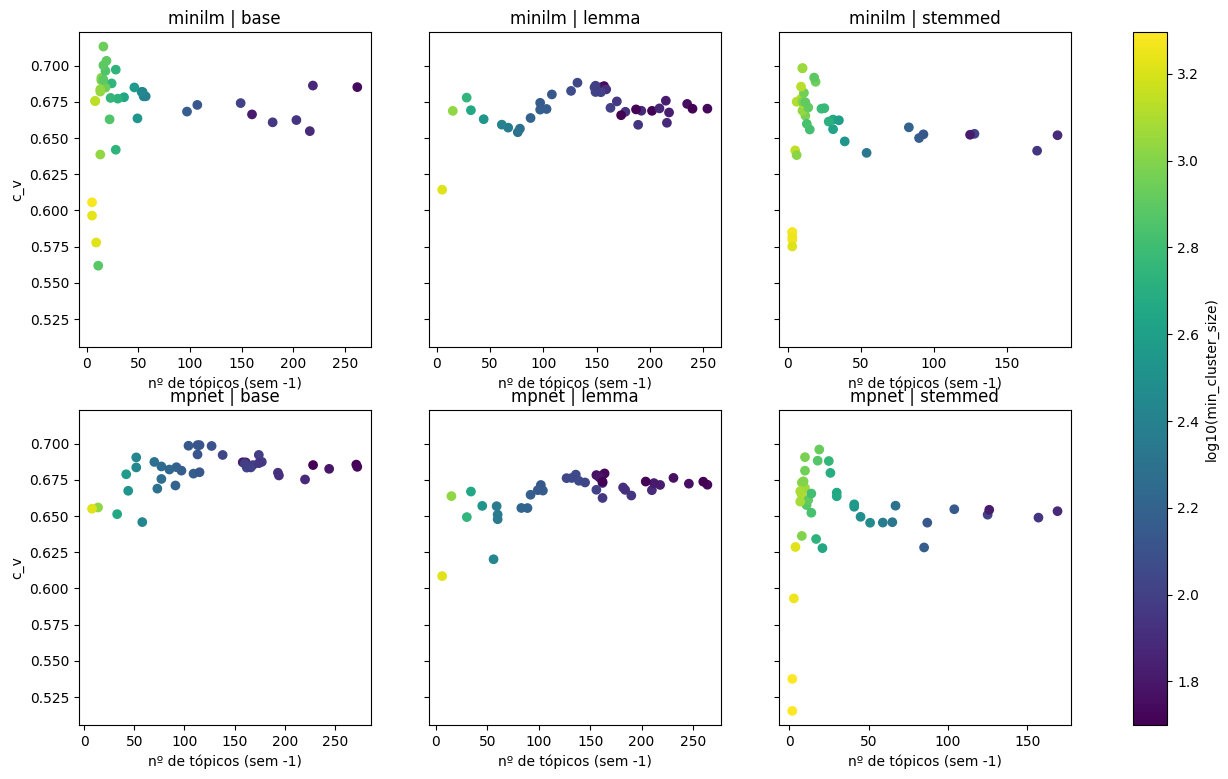

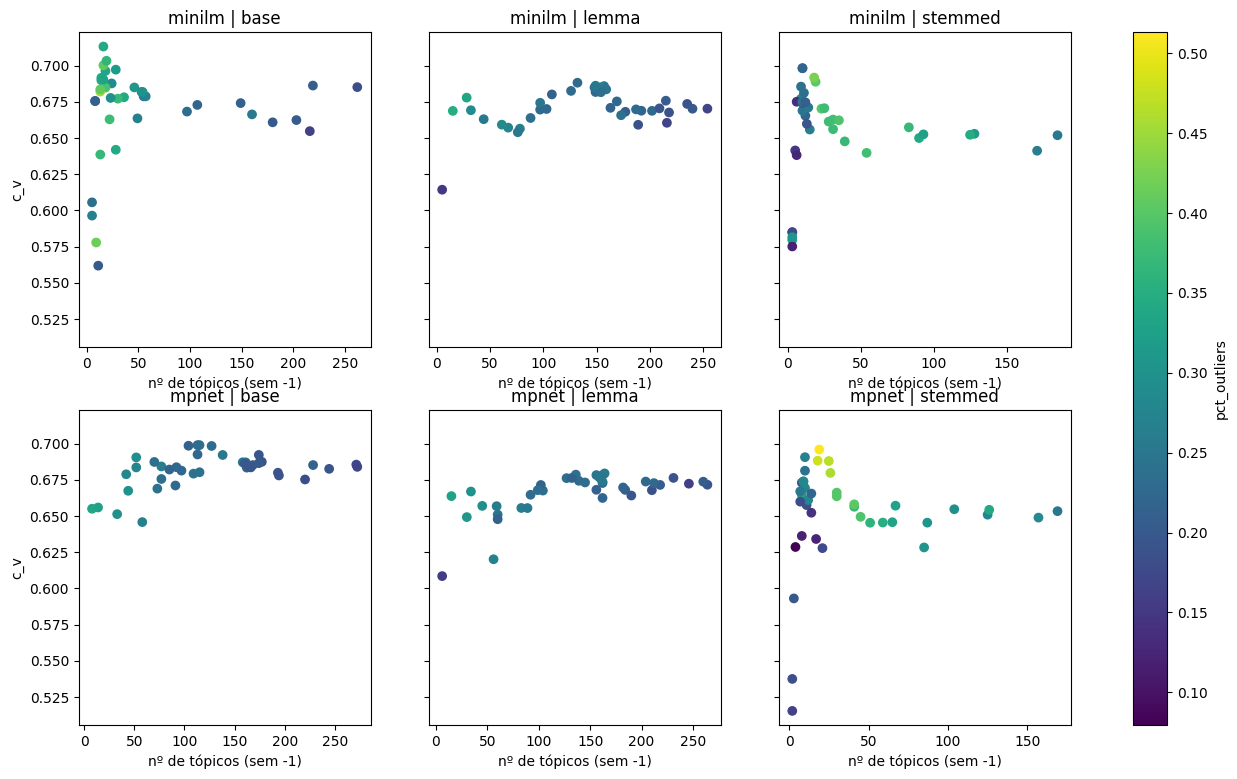

,model,variant,c_v,n_topics,pct_outliers,diversity,n_neighbors,umap_components,min_cluster_size,min_samples
39,minilm,base,0.713171,16,0.340739,0.906250,50,5,866,74
37,minilm,base,0.703319,19,0.362375,0.926316,50,5,792,59
29,minilm,base,0.700223,16,0.406634,0.931250,15,5,786,56
132,mpnet,base,0.698964,115,0.243546,0.742609,30,10,132,46
156,mpnet,base,0.698953,113,0.229317,0.749558,30,10,134,17
128,mpnet,base,0.698526,104,0.216462,0.750000,30,10,135,59
106,minilm,stemmed,0.698200,10,0.238662,0.940000,30,5,1092,8
107,minilm,stemmed,0.698200,10,0.217432,0.940000,30,5,1131,6
236,mpnet,stemmed,0.695913,19,0.513119,0.905263,50,5,836,7
96,minilm,stemmed,0.691738,18,0.425536,0.911111,30,10,781,27


In [12]:
rows = []
for m in MODELS:
    for v in VARIANTS:
        st = optuna.load_study(study_name=f"bertopic_{m}_{v}", storage=STORAGE)
        rows += [{"model": m, "variant": v, "trial": t.number, "c_v": t.value,
                  **t.params, **t.user_attrs}
                 for t in st.trials if t.state == optuna.trial.TrialState.COMPLETE]
res = pd.DataFrame(rows)
res.to_csv(f"{SEARCH_DIR}/results.csv", index=False)

def plot_search(res, color="min_cluster_size", log=True):
    fig, axes = plt.subplots(len(MODELS), len(VARIANTS), figsize=(16, 4.5 * len(MODELS)),
                             sharey=True, squeeze=False)
    col = np.log10(res[color]) if log else res[color]
    norm = plt.Normalize(col.min(), col.max())       # mesma escala de cor em todos os painéis
    for i, m in enumerate(MODELS):
        for j, v in enumerate(VARIANTS):
            ax, k = axes[i, j], (res.model == m) & (res.variant == v)
            sc = ax.scatter(res.loc[k, "n_topics"], res.loc[k, "c_v"],
                            c=col[k], cmap="viridis", norm=norm)
            ax.set_title(f"{m} | {v}")
            ax.set_xlabel("nº de tópicos (sem -1)")
            if j == 0:
                ax.set_ylabel("c_v")
    fig.colorbar(sc, ax=axes, label=f"log10({color})" if log else color)
    plt.show()

plot_search(res)                                   # equivalente ao gráfico do LDA
plot_search(res, color="pct_outliers", log=False)  # mesmo gráfico, cor = % outliers

cols = ["model", "variant", "c_v", "n_topics", "pct_outliers", "diversity",
        "n_neighbors", "umap_components", "min_cluster_size", "min_samples"]
res.sort_values("c_v", ascending=False).groupby(["model", "variant"]).head(3)[cols]